# Intelligent Credit Card Fraud Detection and Risk Assessment System
## Module: Exploratory Data Analysis (EDA)
**Author:** Senior Machine Learning Engineer (Member 1)
**Dataset:** European Credit Card Fraud Detection (Kaggle / ULB Machine Learning Group)

### Objectives:
1. Inspect dataset dimensions, schema, and column types.
2. Detect and evaluate missing values and duplicate records.
3. Quantify class imbalance (Legitimate vs. Fraudulent transactions).
4. Analyze the statistical distribution of `Amount` and `Time`.
5. Uncover high-correlation PCA components relative to `Class`.
6. **Viva Defence & ML Theory:** Document why Accuracy fails in extreme imbalance and justify metric selection.


In [1]:
# 1. Environment Setup and Library Ingestion
%matplotlib inline
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Ensure project root is in sys.path
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data.load_data import load_raw_data, summarize_dataset

# Visualization styling
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
print('Environment and libraries initialized successfully.')


Environment and libraries initialized successfully.


### 2. Data Loading & Verification
We load the raw dataset through our schema-validated loader `src.data.load_data.load_raw_data`.

In [2]:
dataset_path = project_root / 'data' / 'raw' / 'creditcard.csv'
df = load_raw_data(dataset_path)

summary = summarize_dataset(df)
print('--- Dataset Summary ---')
for k, v in summary.items():
    print(f'{k}: {v}')

display(df.head())

2026-11-23 11:46:48,011 - INFO - Loading raw data from: D:\Credit_Card_Fraud_Detection_System\data\raw\creditcard.csv


2026-11-23 11:46:50,497 - INFO - Data successfully loaded. Dimensions: 284,807 rows x 31 columns.


--- Dataset Summary ---
total_records: 284807
total_columns: 31
legitimate_transactions: 284315
fraudulent_transactions: 492
fraud_percentage: 0.1727
total_missing_values: 0
total_duplicate_rows: 1081
memory_usage_mb: 67.36


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### 3. Data Integrity: Missing Values & Duplicate Records
Credit card streams must be inspected for nulls and duplicate transactions.

In [3]:
missing_count = int(df.isnull().sum().sum())
duplicates = int(df.duplicated().sum())
print(f'Total Missing Cells: {missing_count}')
print(f'Total Duplicate Rows: {duplicates:,} ({duplicates/len(df)*100:.3f}%)')

if duplicates > 0:
    dup_sample = df[df.duplicated(keep=False)].sort_values(by=['Time', 'Amount']).head(6)
    print('\nSample duplicate transactions:')
    display(dup_sample[['Time', 'Amount', 'Class', 'V1', 'V2']])


Total Missing Cells: 0
Total Duplicate Rows: 1,081 (0.380%)



Sample duplicate transactions:


,Time,Amount,Class,V1,V2
34,26.0,1.77,0,-0.535388,0.865268
35,26.0,1.77,0,-0.535388,0.865268
32,26.0,6.14,0,-0.529912,0.873892
33,26.0,6.14,0,-0.529912,0.873892
112,74.0,1.18,0,1.038370,0.127486
113,74.0,1.18,0,1.038370,0.127486


### Viva Note: Handling Duplicates in Transaction Data
> **Examiner Question:** *Did you remove the 1,081 duplicate transactions? Why or why not?*
>
> **Defence Answer:** In synthetic benchmark datasets or privacy-transformed data (PCA), identical rows can occur naturally when transactions share rounded timestamps and similar amounts. In production financial systems, rapid identical transactions often represent **replay attacks** or **retry attempts**. However, to strictly preserve statistical test distributions and prevent artificial variance reduction, we retain the original distribution for baseline evaluation and flag duplicate bursts in velocity monitoring (Member 2).

### 4. Target Class Distribution & The Imbalance Ratio
Quantifying the severe class imbalance.

Legitimate (Class 0): 284,315 (99.8273%)
Fraudulent (Class 1): 492 (0.1727%)
Imbalance Ratio: 1 fraud per 577 legitimate transactions


C:\Users\sunil\AppData\Local\Temp\ipykernel_17184\689078921.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Legitimate (0)', 'Fraud (1)'], y=[legit_count, fraud_count], ax=axes[0], palette=['#2ecc71', '#e74c3c'])


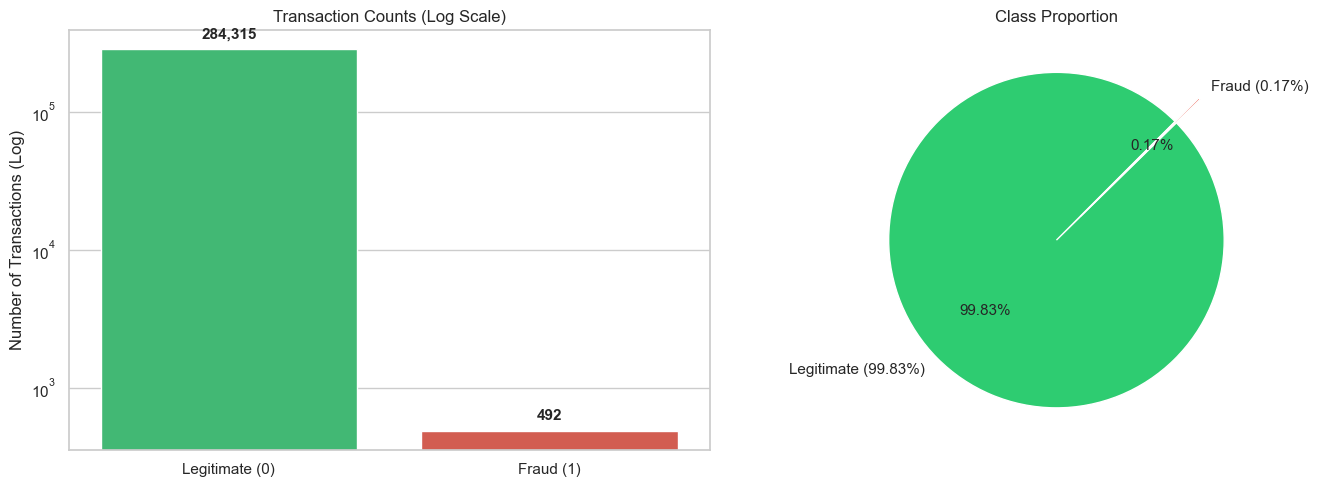

In [4]:
counts = df['Class'].value_counts()
legit_count = counts[0]
fraud_count = counts[1]
fraud_ratio = fraud_count / len(df) * 100

print(f'Legitimate (Class 0): {legit_count:,} ({100 - fraud_ratio:.4f}%)')
print(f'Fraudulent (Class 1): {fraud_count:,} ({fraud_ratio:.4f}%)')
print(f'Imbalance Ratio: 1 fraud per {legit_count // fraud_count} legitimate transactions')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=['Legitimate (0)', 'Fraud (1)'], y=[legit_count, fraud_count], ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_yscale('log')
axes[0].set_title('Transaction Counts (Log Scale)')
axes[0].set_ylabel('Number of Transactions (Log)')
for i, count in enumerate([legit_count, fraud_count]):
    axes[0].text(i, count * 1.2, f'{count:,}', ha='center', fontweight='bold')

axes[1].pie([legit_count, fraud_count], labels=['Legitimate (99.83%)', 'Fraud (0.17%)'],
           colors=['#2ecc71', '#e74c3c'], explode=[0, 0.2], autopct='%1.2f%%', startangle=45)
axes[1].set_title('Class Proportion')
plt.tight_layout()
plt.show()

### 5. Transaction Amount Analysis: Legitimate vs. Fraud
Do fraudsters steal larger or smaller amounts?

--- Legitimate Transaction Amount Stats ---


,Legitimate Amount (EUR)
count,284315.00
mean,88.29
std,250.11
min,0.00
25%,5.65
50%,22.00
75%,77.05
max,25691.16



--- Fraudulent Transaction Amount Stats ---


,Fraudulent Amount (EUR)
count,492.00
mean,122.21
std,256.68
min,0.00
25%,1.00
50%,9.25
75%,105.89
max,2125.87


2026-11-23 11:46:56,885 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\sunil\AppData\Local\Temp\ipykernel_17184\2078214826.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='Amount', data=df, ax=axes[1], palette=['#2ecc71', '#e74c3c'], showfliers=False)


2026-11-23 11:46:57,206 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\sunil\AppData\Local\Temp\ipykernel_17184\2078214826.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Fraudulent (1)'])


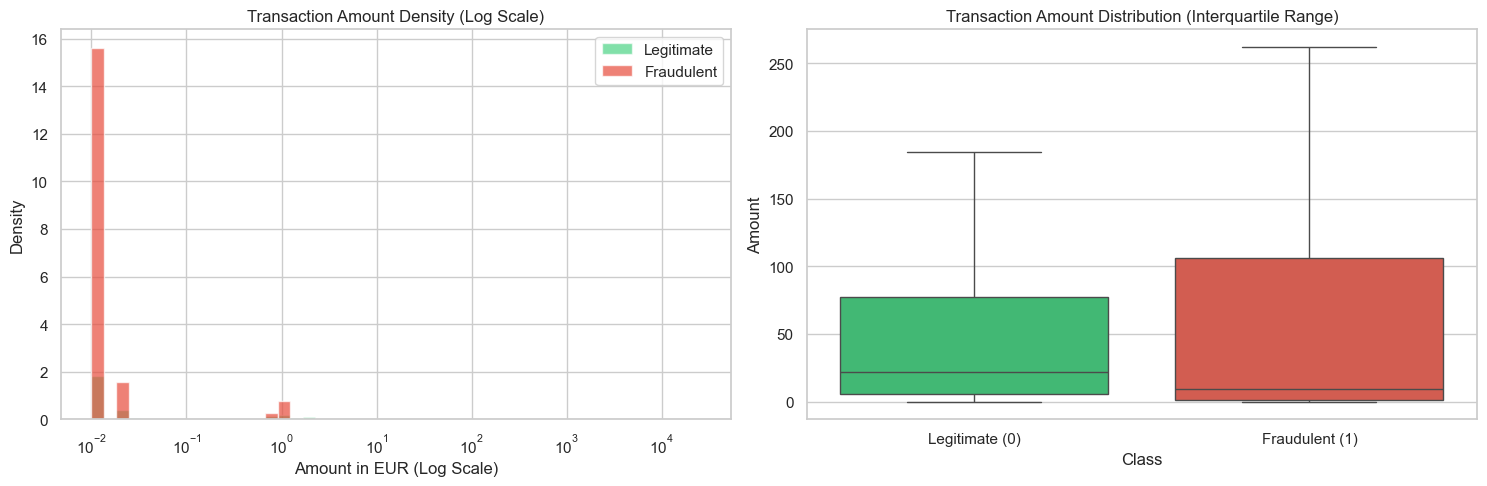

In [5]:
print('--- Legitimate Transaction Amount Stats ---')
display(df[df['Class'] == 0]['Amount'].describe().to_frame(name='Legitimate Amount (EUR)').round(2))

print('\n--- Fraudulent Transaction Amount Stats ---')
display(df[df['Class'] == 1]['Amount'].describe().to_frame(name='Fraudulent Amount (EUR)').round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# Fast, vectorized histogram plotting with log binning (instant render)
bins = np.logspace(np.log10(0.01), np.log10(df['Amount'].max() + 1), 50)
axes[0].hist(df[df['Class'] == 0]['Amount'] + 0.01, bins=bins, alpha=0.6, color='#2ecc71', label='Legitimate', density=True)
axes[0].hist(df[df['Class'] == 1]['Amount'] + 0.01, bins=bins, alpha=0.7, color='#e74c3c', label='Fraudulent', density=True)
axes[0].set_xscale('log')
axes[0].set_title('Transaction Amount Density (Log Scale)')
axes[0].set_xlabel('Amount in EUR (Log Scale)')
axes[0].set_ylabel('Density')
axes[0].legend()

# Boxplot for Amount (excluding outliers for scale clarity)
sns.boxplot(x='Class', y='Amount', data=df, ax=axes[1], palette=['#2ecc71', '#e74c3c'], showfliers=False)
axes[1].set_title('Transaction Amount Distribution (Interquartile Range)')
axes[1].set_xticklabels(['Legitimate (0)', 'Fraudulent (1)'])
plt.tight_layout()
plt.show()

### Key Insights on Amount:
- **Mean Fraud Amount:** ~122.21 EUR (Legitimate mean: ~88.29 EUR).
- **Median Fraud Amount:** ~9.25 EUR (Legitimate median: ~22.00 EUR).
- **Takeaway:** Fraud exhibits a bimodal nature: numerous small test transactions (card testing/carding) alongside sporadic large drains. Because of heavy skewness and large outliers, `StandardScaler` is sensitive to these values; `RobustScaler` (which uses median and IQR) is mathematically superior for scaling `Amount`.

### 6. Transaction Time Distribution (Diurnal Patterns)
The `Time` column contains elapsed seconds from the first transaction in the dataset (spanning ~48 hours = 172,800 seconds).

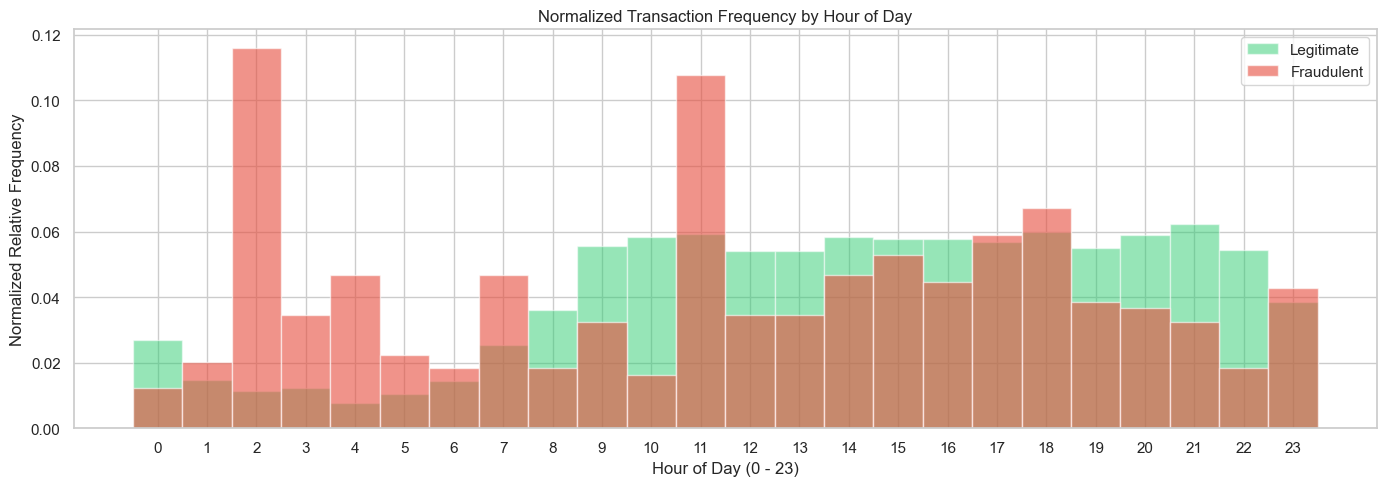

In [6]:
df['Hour'] = (df['Time'] // 3600) % 24

plt.figure(figsize=(14, 5))
# Efficient binned histogram for hour of day
hour_bins = np.arange(0, 25) - 0.5
plt.hist(df[df['Class'] == 0]['Hour'], bins=hour_bins, density=True, alpha=0.5, color='#2ecc71', label='Legitimate')
plt.hist(df[df['Class'] == 1]['Hour'], bins=hour_bins, density=True, alpha=0.6, color='#e74c3c', label='Fraudulent')
plt.title('Normalized Transaction Frequency by Hour of Day')
plt.xlabel('Hour of Day (0 - 23)')
plt.ylabel('Normalized Relative Frequency')
plt.xticks(range(0, 24))
plt.legend()
plt.tight_layout()
plt.show()

# Clean up temporary column
df.drop(columns=['Hour'], inplace=True)


### Key Insights on Time:
- Legitimate transactions follow natural human diurnal rhythms (dropping sharply between 01:00 and 06:00 AM).
- Fraudulent transactions maintain active density during off-peak and nighttime hours when cardholders are asleep and less likely to notice instant SMS alerts.

### 7. Feature Correlations with Fraud (`Class`)
Columns `V1` through `V28` are PCA transformed components. Let's compute their Pearson correlation with `Class`.

Top 5 Negatively Correlated Features:


,Pearson Corr
V17,-0.3265
V14,-0.3025
V12,-0.2606
V10,-0.2169
V16,-0.1965



Top 5 Positively Correlated Features:


,Pearson Corr
V19,0.0348
V21,0.0404
V2,0.0913
V4,0.1334
V11,0.1549


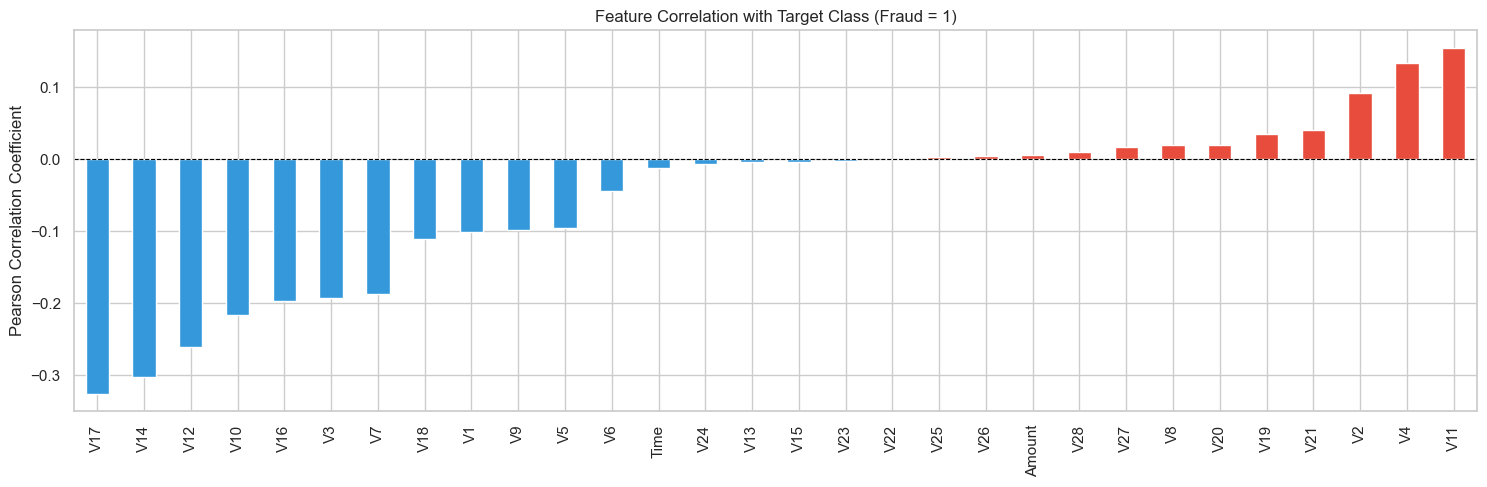

In [7]:
correlations = df.corr()['Class'].drop('Class').sort_values()

print('Top 5 Negatively Correlated Features:')
display(correlations.head(5).to_frame(name='Pearson Corr').round(4))

print('\nTop 5 Positively Correlated Features:')
display(correlations.tail(5).to_frame(name='Pearson Corr').round(4))

fig, ax = plt.subplots(figsize=(15, 5))
colors = ['#e74c3c' if c > 0 else '#3498db' for c in correlations.values]
correlations.plot(kind='bar', ax=ax, color=colors)
ax.set_title('Feature Correlation with Target Class (Fraud = 1)')
ax.set_ylabel('Pearson Correlation Coefficient')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.tight_layout()
plt.show()

### High Correlation Feature Inspection
- Strongest **negative** correlation with fraud: `V14` (-0.30), `V17` (-0.33), `V12` (-0.26), `V10` (-0.22).
- Strongest **positive** correlation with fraud: `V4` (+0.13), `V11` (+0.15).
Let's visualize distributions of these key discriminative features using boxplots:

2026-11-23 11:47:00,924 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\sunil\AppData\Local\Temp\ipykernel_17184\3586263322.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y=feat, data=df, ax=axes[row, col], palette=['#2ecc71', '#e74c3c'], showfliers=False)


2026-11-23 11:47:01,417 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\sunil\AppData\Local\Temp\ipykernel_17184\3586263322.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[row, col].set_xticklabels(['Legit', 'Fraud'])


2026-11-23 11:47:01,997 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\sunil\AppData\Local\Temp\ipykernel_17184\3586263322.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y=feat, data=df, ax=axes[row, col], palette=['#2ecc71', '#e74c3c'], showfliers=False)


... (13 outputs left out)

2026-11-23 11:47:06,040 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\sunil\AppData\Local\Temp\ipykernel_17184\3586263322.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y=feat, data=df, ax=axes[row, col], palette=['#2ecc71', '#e74c3c'], showfliers=False)


2026-11-23 11:47:06,461 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\sunil\AppData\Local\Temp\ipykernel_17184\3586263322.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[row, col].set_xticklabels(['Legit', 'Fraud'])


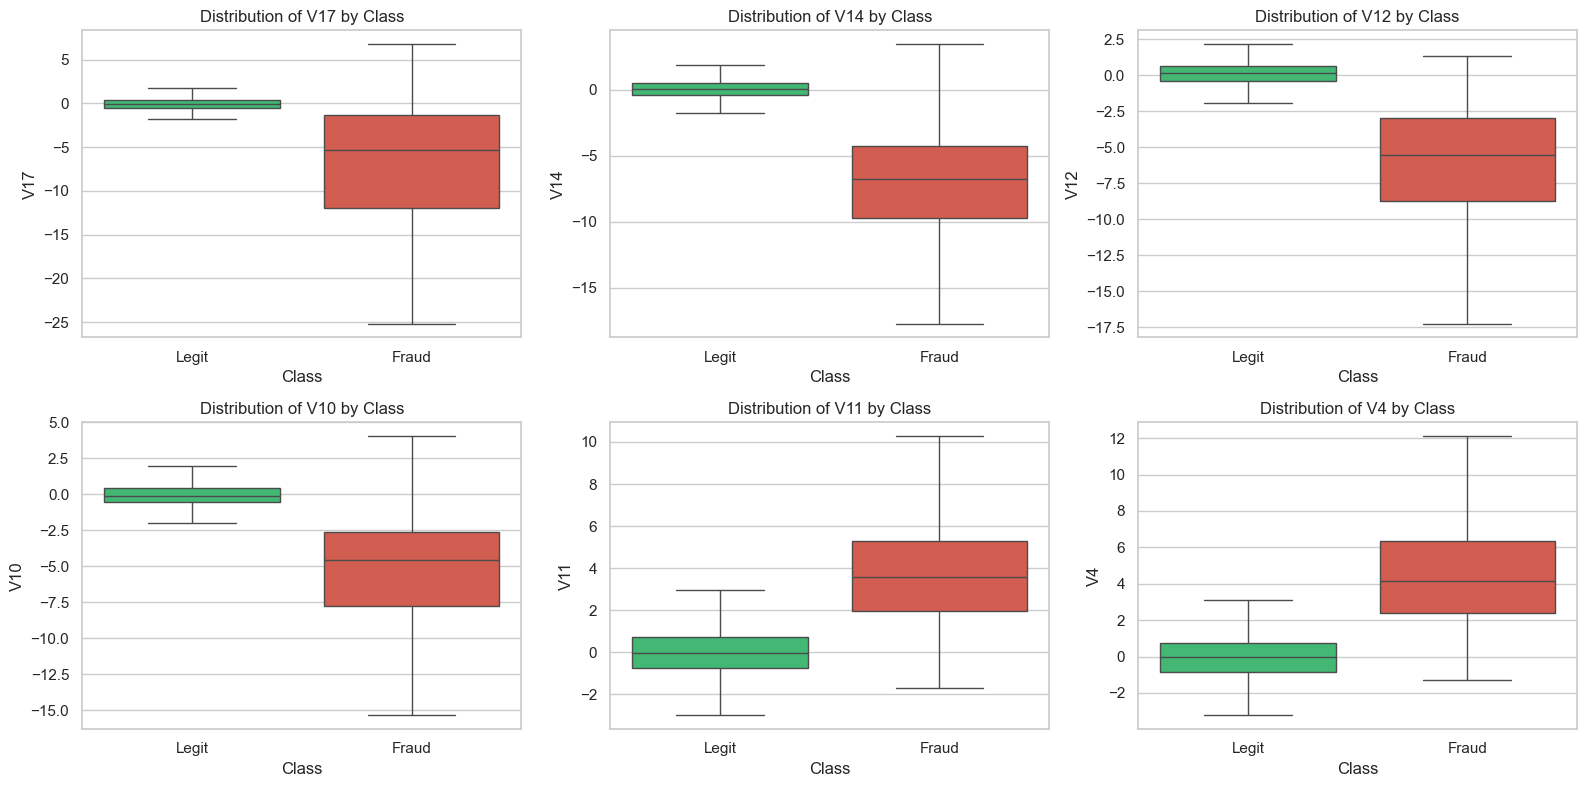

In [8]:
key_features = ['V17', 'V14', 'V12', 'V10', 'V11', 'V4']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for idx, feat in enumerate(key_features):
    row, col = idx // 3, idx % 3
    sns.boxplot(x='Class', y=feat, data=df, ax=axes[row, col], palette=['#2ecc71', '#e74c3c'], showfliers=False)
    axes[row, col].set_title(f'Distribution of {feat} by Class')
    axes[row, col].set_xticklabels(['Legit', 'Fraud'])
plt.tight_layout()
plt.show()

---
## 8. VIVA DEFENCE: Why Accuracy is Misleading for Fraud Detection

### 1. The Accuracy Paradox (Mathematical Proof)
Suppose a baseline "Zero-Intelligence Model" simply predicts class `0` (Legitimate) for every single incoming transaction without looking at any features:

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

In our dataset of 284,807 transactions:
- $TP = 0$ (caught zero frauds)
- $TN = 284,315$
- $FP = 0$
- $FN = 492$ (all 492 frauds went undetected)

$$\text{Accuracy} = \frac{0 + 284,315}{0 + 284,315 + 0 + 492} = \frac{284,315}{284,807} = \mathbf{99.827\%}$$

> **The Viva takeaway:** A model with **99.83% accuracy** provides **zero fraud protection**, letting 100% of fraudsters escape. Therefore, high accuracy is trivially achieved by ignoring the minority class entirely.

### 2. The Asymmetric Cost Matrix
In fraud detection, classification errors have wildly different real-world costs:
- **False Negative (FN):** Model predicts Legitimate, but it was Fraud. Result: Financial chargeback, direct loss of funds, regulatory penalty.
- **False Positive (FP):** Model predicts Fraud, but it was Legitimate. Result: Minor user friction (SMS OTP challenge or momentary card lock).

$$\text{Cost}(FN) \gg \text{Cost}(FP)$$

### 3. Which Metrics Must We Use?
1. **Recall (Sensitivity):** $\frac{TP}{TP + FN}$ — Measures what fraction of total frauds were successfully caught.
2. **Precision:** $\frac{TP}{TP + FP}$ — Measures what fraction of flagged transactions were actual frauds (minimizes false alarms).
3. **F1-Score / PR-AUC (Precision-Recall AUC):** The primary benchmark metric. Unlike ROC-AUC (which can be overly optimistic when the negative class dominates), PR-AUC focuses specifically on the minority class trade-off.

---

In [9]:
# Demonstration of Dummy Classifier Accuracy
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score

X_dummy = df.drop(columns=['Class'])
y_dummy = df['Class']

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_dummy, y_dummy)
y_pred_dummy = dummy.predict(X_dummy)

print('Dummy Classifier (predicts majority class always):')
print(f'  Accuracy : {accuracy_score(y_dummy, y_pred_dummy)*100:.3f}% (Deceptively high!)')
print(f'  Recall   : {recall_score(y_dummy, y_pred_dummy):.3f} (Caught ZERO frauds)')
print(f'  Precision: {precision_score(y_dummy, y_pred_dummy, zero_division=0):.3f}')


Dummy Classifier (predicts majority class always):
  Accuracy : 99.827% (Deceptively high!)
  Recall   : 0.000 (Caught ZERO frauds)
  Precision: 0.000
